<a href="https://colab.research.google.com/github/YaroslavKarsim/MachLearning/blob/main/%D0%9B%D0%A0_2_2_%D0%9C%D0%9D_%D0%9A%D0%B0%D1%80%D1%81%D1%96%D0%BC_%D0%AF%D1%80%D0%BE%D1%81%D0%BB%D0%B0%D0%B2_4_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

In [14]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mahmoudshogaa/titanic-dataset")
print("Path to dataset files:", path)

100%|██████████| 22.0k/22.0k [00:00<00:00, 9.27MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/mahmoudshogaa/titanic-dataset/versions/1


In [15]:
df = pd.read_csv(os.path.join(path, "titanic.csv"))
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [17]:
df.duplicated().sum

<bound method Series.sum of 0      False
1      False
2      False
3      False
4      False
       ...  
886    False
887    False
888    False
889    False
890    False
Length: 891, dtype: bool>

In [18]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [19]:
df['Age'] = df['Age'].fillna(df['Age'].median(skipna=True))


df.drop(['Cabin'], axis=1, inplace=True)

df.drop(['Embarked'], axis=1, inplace=True)

In [20]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [21]:
df = df[['Survived', 'Pclass', 'Sex', 'Age', 'Fare']]
df.head()

,Survived,Pclass,Sex,Age,Fare
0,0,3,male,22.0,7.2500
1,1,1,female,38.0,71.2833
2,1,3,female,26.0,7.9250
3,1,1,female,35.0,53.1000
4,0,3,male,35.0,8.0500


In [22]:
df['Sex'].value_counts()

,count
Sex,
male,577
female,314


In [23]:
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

print(f'Data types of the dataset:\n{df.dtypes}')

Data types of the dataset:
Survived      int64
Pclass        int64
Sex           int64
Age         float64
Fare        float64
dtype: object


/tmp/ipykernel_877/275882515.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})


In [24]:
df.describe()

,Survived,Pclass,Sex,Age,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,0.352413,29.361582,32.204208
std,0.486592,0.836071,0.477990,13.019697,49.693429
min,0.000000,1.000000,0.000000,0.420000,0.000000
25%,0.000000,2.000000,0.000000,22.000000,7.910400
50%,0.000000,3.000000,0.000000,28.000000,14.454200
75%,1.000000,3.000000,1.000000,35.000000,31.000000
max,1.000000,3.000000,1.000000,80.000000,512.329200


In [25]:
df.isnull().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,0
Fare,0


In [26]:
df.head()

,Survived,Pclass,Sex,Age,Fare
0,0,3,0,22.0,7.2500
1,1,1,1,38.0,71.2833
2,1,3,1,26.0,7.9250
3,1,1,1,35.0,53.1000
4,0,3,0,35.0,8.0500


In [27]:
df.tail()

,Survived,Pclass,Sex,Age,Fare
886,0,2,0,27.0,13.00
887,1,1,1,19.0,30.00
888,0,3,1,28.0,23.45
889,1,1,0,26.0,30.00
890,0,3,0,32.0,7.75


In [28]:
survival_by_sex = df.groupby('Sex')['Survived'].mean() * 100

print(f'Share of survived males: {survival_by_sex[0]:.2f}%')
print(f'Share of survived females: {survival_by_sex[1]:.2f}%')

Share of survived males: 18.89%
Share of survived females: 74.20%


In [29]:
print(f'Correlation between sex and survival: {df["Sex"].corr(df["Survived"])}')

Correlation between sex and survival: 0.5433513806577555


In [30]:
class1_surv_rate = df[(df['Pclass'] == 1) & (df['Survived'] == 1)].shape[0] / df[df['Pclass'] == 1].shape[0]
class2_surv_rate = df[(df['Pclass'] == 2) & (df['Survived'] == 1)].shape[0] / df[df['Pclass'] == 2].shape[0]
class3_surv_rate = df[(df['Pclass'] == 3) & (df['Survived'] == 1)].shape[0] / df[df['Pclass'] == 3].shape[0]


print(f'Share of survived class 1 passengers {class1_surv_rate * 100:.2f}%')
print(f'Share of survived class 2 passengers {class2_surv_rate * 100:.2f}%')
print(f'Share of survived class 3 passengers {class3_surv_rate * 100:.2f}%')

Share of survived class 1 passengers 62.96%
Share of survived class 2 passengers 47.28%
Share of survived class 3 passengers 24.24%


In [63]:
import pandas as pd
import requests
from io import StringIO
url = 'https://uk.wikipedia.org/wiki/%D0%9D%D0%B0%D1%81%D0%B5%D0%BB%D0%B5%D0%BD%D0%BD%D1%8F_%D0%A3%D0%BA%D1%80%D0%B0%D1%97%D0%BD%D0%B8#%D0%9D%D0%B0%D1%80%D0%BE%D0%B4%D0%B6%D1%83%D0%B2%D0%B0%D0%BD%D1%96%D1%81%D1%82%D1%8C%22'

headers = {
"User-Agent": "Mozilla/5.0",
"Accept-Language": "uk-UA,uk;q=0.9,en;q=0.8",
}

html = requests.get(url, headers=headers, timeout=30).text

df = pd.read_html(
StringIO(html),
match="Коефіцієнт народжуваності в регіонах України",
thousands=".", decimal=","
)[0]

df

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,—,—
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,—
5,Житомирська,26.1,22.3,15.9,12.9,8.9,12.2,12.0,7.9
6,Закарпатська,31.4,27.3,20.7,16.8,11.5,15.1,14.6,10.4
7,Запорізька,21.9,19.7,15.0,12.4,7.1,10.6,10.6,6.8
8,Івано-Франківська,24.3,24.8,18.2,15.5,10.3,12.4,12.2,8.8
9,Київська,20.4,18.9,15.6,12.3,7.3,12.2,12.1,8.0


In [66]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Регіон  28 non-null     object 
 1   1950    26 non-null     float64
 2   1960    27 non-null     float64
 3   1970    27 non-null     float64
 4   1990    28 non-null     float64
 5   2000    28 non-null     float64
 6   2012    28 non-null     float64
 7   2014    28 non-null     object 
 8   2019    28 non-null     object 
dtypes: float64(6), object(3)
memory usage: 2.1+ KB


In [67]:
df = df.replace(['—', '—N/a', '..', ' ', ''], np.nan)
for col in df.columns[1:]:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("Пропущені значення до обробки:")
print(df.isnull().sum())




Пропущені значення до обробки:
Регіон    0
1950      2
1960      1
1970      1
1990      0
2000      0
2012      0
2014      2
2019      4
dtype: int64


In [68]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].mean())

print("\nПропущені значення після обробки:")
print(df.isnull().sum())


Пропущені значення після обробки:
Регіон    0
1950      0
1960      0
1970      0
1990      0
2000      0
2012      0
2014      0
2019      0
dtype: int64


In [69]:
df.head()

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,11.142308,8.020833
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.900000,7.600000
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.100000,10.100000
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.100000,7.100000
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.200000,8.020833


In [70]:
df.tail()

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
23,Чернівецька,24.700000,21.800000,17.000000,14.8,10.1,12.8,12.900000,9.200000
24,Чернігівська,22.000000,18.300000,12.700000,10.8,6.9,9.4,9.000000,6.100000
25,Київ,23.092308,17.400000,15.900000,12.0,7.3,12.0,12.100000,11.000000
26,Севастополь,23.092308,20.748148,15.585185,12.5,7.0,12.0,11.142308,8.020833
27,Україна,22.800000,20.500000,15.200000,12.6,7.8,11.4,11.100000,8.100000


In [81]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.describe()

,1950,1960,1970,1990,2000,2012
count,26.000000,27.000000,27.000000,28.000000,28.000000,28.000000
mean,23.092308,20.748148,15.585185,13.042857,8.207143,11.646429
std,2.822045,2.936032,1.870357,1.527872,1.556808,1.636274
min,18.600000,16.300000,12.700000,10.800000,6.100000,9.400000
25%,21.150000,18.650000,14.400000,12.225000,7.075000,10.450000
50%,22.600000,20.400000,15.200000,12.600000,7.850000,11.450000
75%,24.600000,22.050000,16.300000,14.050000,8.950000,12.250000
max,31.400000,27.300000,20.700000,16.800000,11.800000,15.900000


/tmp/ipykernel_877/234587432.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=latest_year_col, y=region_col, data=df_sorted, palette="crest")


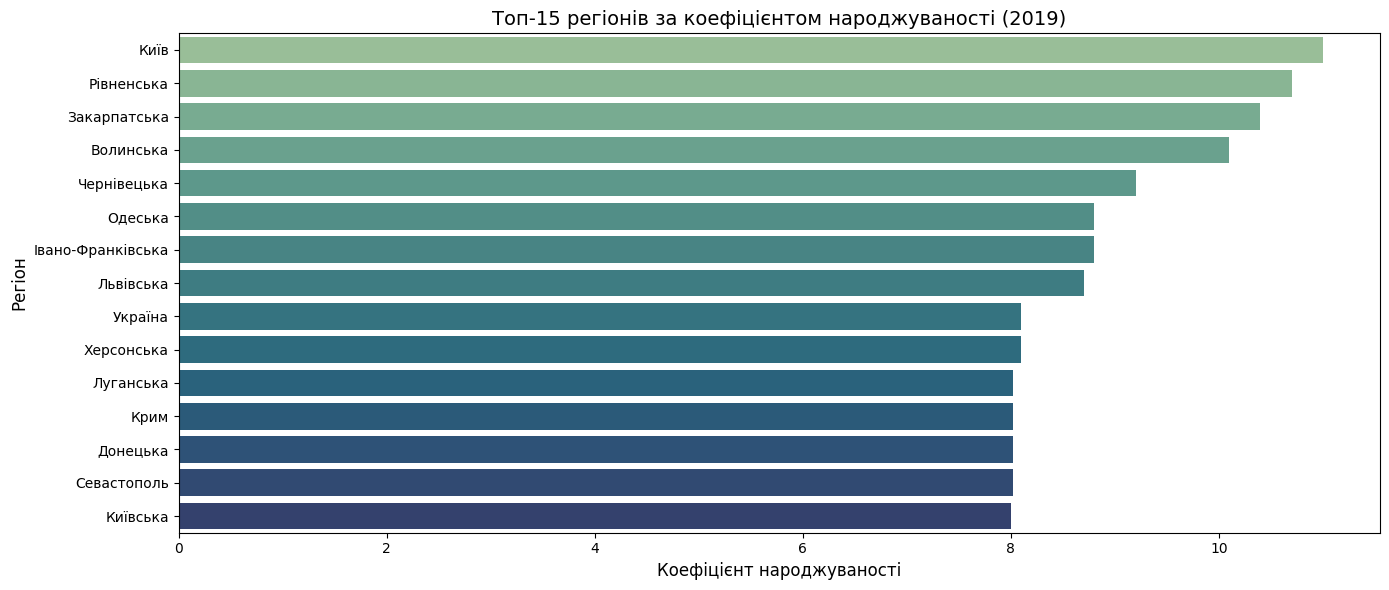

In [55]:
plt.figure(figsize=(14, 6))
region_col = df.columns[0]
latest_year_col = df.columns[-1]

df_sorted = df.sort_values(by=latest_year_col, ascending=False).head(15)

sns.barplot(x=latest_year_col, y=region_col, data=df_sorted, palette="crest")
plt.title(f"Топ-15 регіонів за коефіцієнтом народжуваності ({latest_year_col})", fontsize=14)
plt.xlabel("Коефіцієнт народжуваності", fontsize=12)
plt.ylabel("Регіон", fontsize=12)
plt.tight_layout()
plt.show()

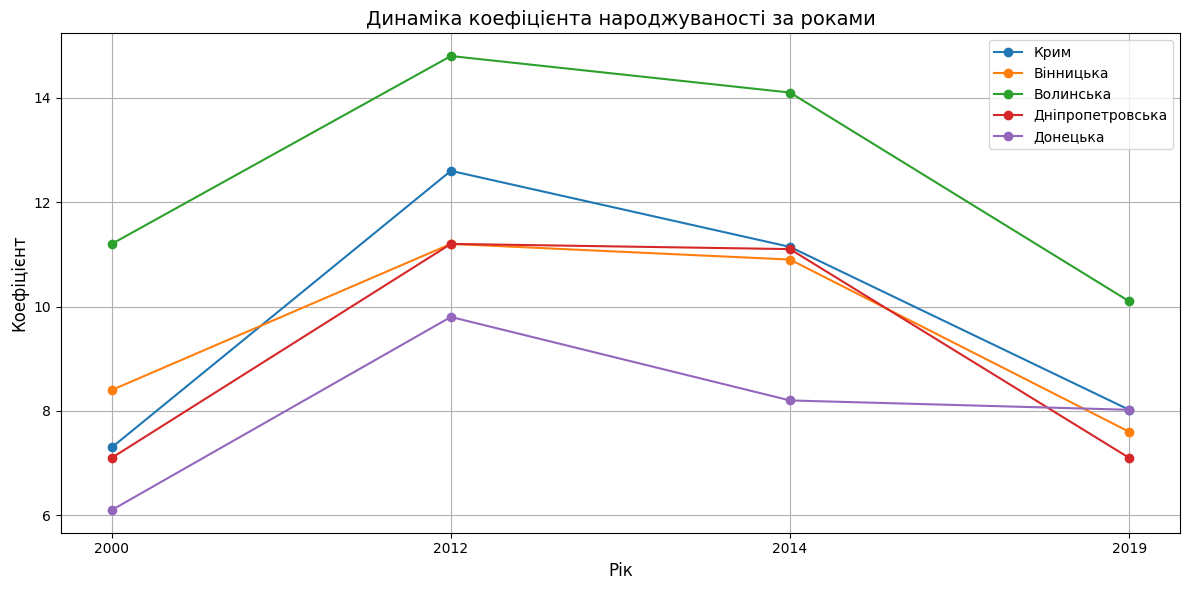

In [59]:
year_columns = [col for col in df.columns if any(str(y) in str(col) for y in range(2000, 2030))]

if len(year_columns) > 1:
    plt.figure(figsize=(12, 6))
    for idx, row in df.head(5).iterrows():
        plt.plot(year_columns, row[year_columns].values, marker='o', label=row[region_col])

    plt.title("Динаміка коефіцієнта народжуваності за роками", fontsize=14)
    plt.xlabel("Рік", fontsize=12)
    plt.ylabel("Коефіцієнт", fontsize=12)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

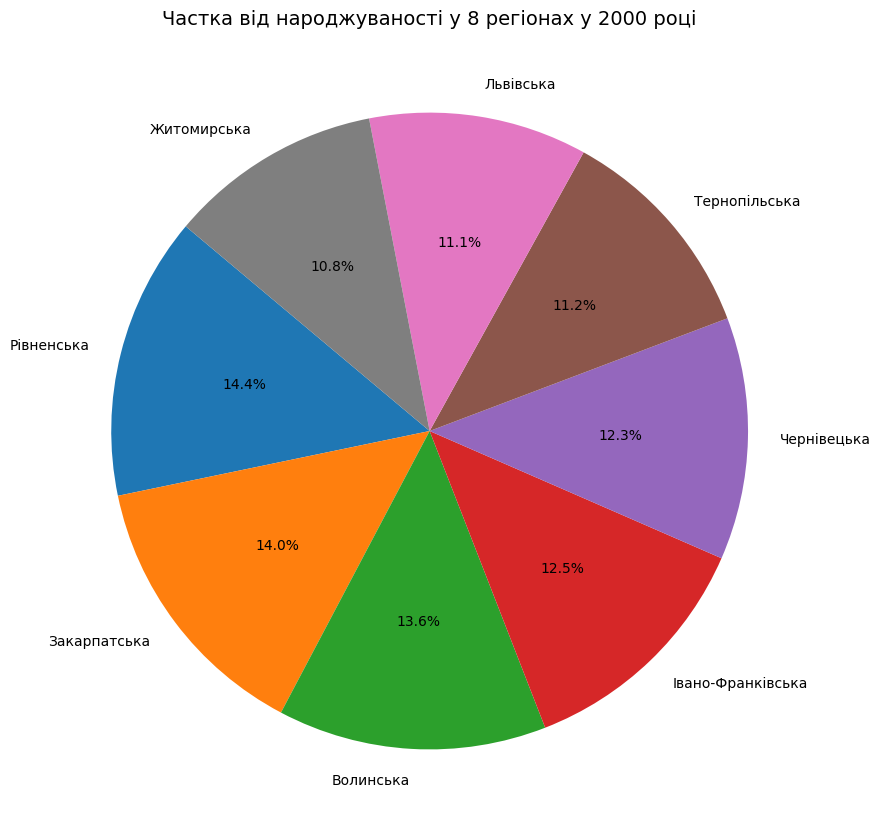

In [80]:
plt.figure(figsize=(9, 9))
region_col = df.columns[0]
year_col = '2000'
df_sorted = df.sort_values(by=year_col, ascending=False).head(8)

plt.pie(df_sorted[year_col], labels=df_sorted[region_col], autopct='%1.1f%%', startangle=140)
plt.title(f"Частка від народжуваності у 8 регіонах у {year_col} році", fontsize=14)
plt.tight_layout()
plt.show()